# Lession 6.4 - ANN Models

**Objectives**

- Build ANN regression models between co2 emissions and temperature change
- Explore ANN model performance tuning with different number of neurons

## 1. Import python packages: matplotlib, pandas, numpy ...

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

## 2. Read CO2 emission data from csv file

In [2]:
data_file_path = "https://raw.githubusercontent.com/owid/co2-data/refs/heads/master/owid-co2-data.csv"
co2_emission = pd.read_csv(data_file_path, sep=",")

## 3. Data preprocessing

- Filter `country` to `World`
- Select necessary columns:
  - `year`
  - `oil_co2`: Annual emissions of carbon dioxide (CO₂) from oil, measured in million tonnes (Mt)
  - `gas_co2`: Annual emissions of carbon dioxide (CO₂) from gas, measured in million tonnes (Mt)
  - `coal_co2`: Annual emissions of carbon dioxide (CO₂) from coal, measured in million tonnes (Mt)
  - `flaring_co2`: Annual emissions of carbon dioxide (CO₂) from flaring, measured in million tonnes (Mt)
  - `cement_co2`: Annual emissions of carbon dioxide (CO₂) from cement, measured in million tonnes (Mt)
  - `temperature_change_from_co2`: Change in global mean surface temperature caused by CO₂ emissions,Measured in °C
- Sort the data by year in ascending order
- Drop NULL vaules
- Reset row index

In [3]:
world_co2_df = (
    co2_emission.loc[
        co2_emission["country"] == "World",
        [
            "year",
            "oil_co2",
            "gas_co2",
            "coal_co2",
            "flaring_co2",
            "cement_co2",
            "temperature_change_from_co2",
        ],
    ]
    .sort_values(by="year", ascending=True)
    .dropna(
        subset=[
            "oil_co2",
            "gas_co2",
            "coal_co2",
            "flaring_co2",
            "cement_co2",
            "temperature_change_from_co2",
        ]
    )
    .reset_index(drop=True)
)

In [4]:
world_co2_df.describe()

,year,oil_co2,gas_co2,coal_co2,flaring_co2,cement_co2,temperature_change_from_co2
count,75.000000,75.000000,75.000000,75.000000,75.000000,75.000000,75.000000
mean,1987.000000,8155.534160,3627.549267,8744.799413,268.551627,649.159000,0.674013
std,21.794495,3289.629391,2328.548960,3761.322295,115.534376,497.916464,0.272183
min,1950.000000,1551.783000,353.156000,3879.955000,73.624000,66.900000,0.297000
25%,1968.500000,5753.330000,1634.235500,5434.125500,166.339500,262.936000,0.432500
50%,1987.000000,9037.386000,3281.567000,8361.174000,323.111000,458.382000,0.633000
75%,2005.500000,10928.458000,5453.647500,11817.369000,358.205000,1007.035000,0.886000
max,2024.000000,12470.596000,8009.828000,15805.254000,432.392000,1666.885000,1.216000


## 4. Plots Between `Inputs` (oil, gas, flaring, cement, coal co2) and `Target` (temperature change)

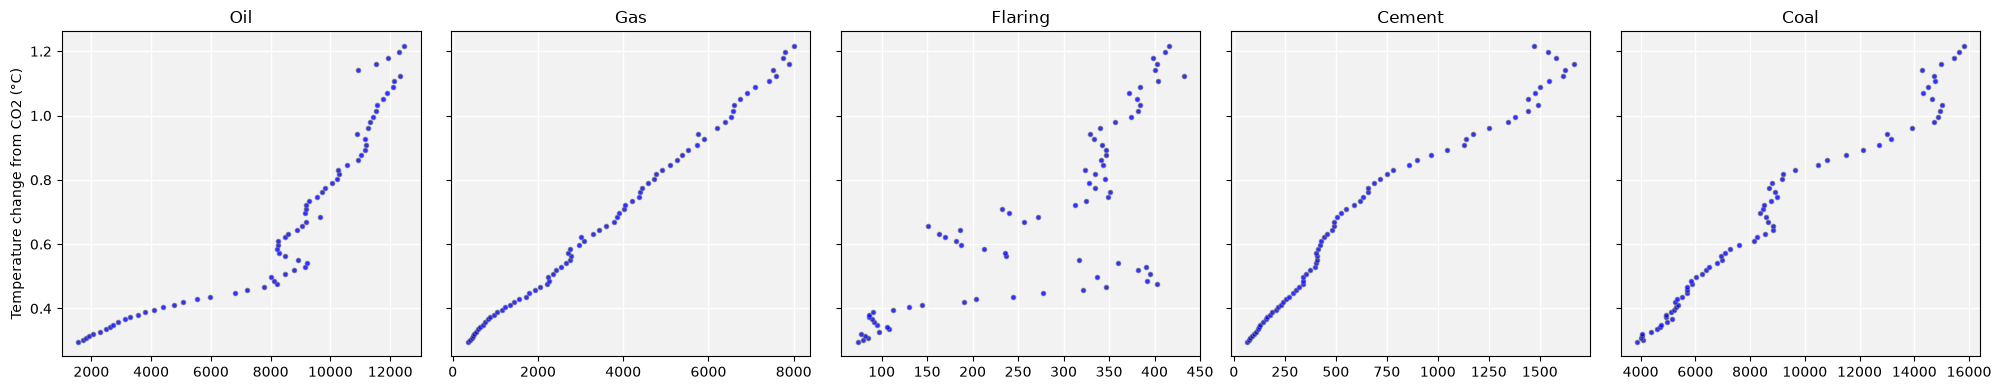

In [5]:
sources = ["oil_co2", "gas_co2", "flaring_co2", "cement_co2", "coal_co2"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, col in zip(axes, sources):
    ax.scatter(
        world_co2_df[col],
        world_co2_df["temperature_change_from_co2"],
        c="blue",  # color of the points
        s=12,  # size of the points
        edgecolor="grey",  # edge color of the points
        linewidth=0.6,  # edge line width of the points
        alpha=0.8,  # transparency of the points
    )
    ax.set_title(col.replace("_co2", "").capitalize())
axes[0].set_ylabel("Temperature change from CO2 (°C)")

fig.set_facecolor("white")  # the whole figure (outside the axes)
for ax in axes:
    ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)
    ax.grid(color="white", linewidth=1)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

## 5. Build ANN Models for Regression

In [6]:
# Split the data into training (70%) and test sets (30%)

from sklearn.model_selection import train_test_split

X = world_co2_df.loc[:, "oil_co2":"cement_co2"]
y = world_co2_df.loc[:, "temperature_change_from_co2"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print(
    f"X_train shape: {X_train.shape}, percentage of training data: {X_train.shape[0] / X.shape[0]:.2%}"
)
print(
    f"X_test shape: {X_test.shape}, percentage of test data: {X_test.shape[0] / X.shape[0]:.2%}"
)

X_train shape: (52, 5), percentage of training data: 69.33%
X_test shape: (23, 5), percentage of test data: 30.67%


In [7]:
# Standardize the features using StandardScaler

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Reference: https://scikit-learn.org/stable/modules/neural_networks_supervised.html

<img src="https://raw.githubusercontent.com/shuhua-wang/data-science-and-machine-learning-courses/main/tutorial/06-supervised-learning/hidden-layer-sizes.png" alt="Hidden Layer Sizes" width="600">

```
sklearn.neural_network.MLPRegressor(
    loss='squared_error',
    hidden_layer_sizes=(100,),
    activation='relu',
    solver='adam',
    learning_rate='constant',
    learning_rate_init=0.001,
    max_iter=200,
)
```

- `loss`: {‘squared_error’, ‘poisson’}, default=’squared_error’
- `hidden_layer_sizes`: default=(100,), The ith element represents the number of neurons in the ith hidden layer
- `activation`: {‘identity’, ‘logistic’, ‘tanh’, ‘relu’}, default=’relu’
- `solver`: {‘lbfgs’, ‘sgd’, ‘adam’}, default=’adam’, the solver for weight optimization
- `learning_rate`: {‘constant’, ‘invscaling’, ‘adaptive’}, default=’constant’, Learning rate schedule for weight updates.
- `learning_rate_init`: `float`, default=0.001, The initial learning rate used.
- `max_iter`: `int`, default=200


In [8]:
from sklearn.neural_network import MLPRegressor

# Fit an artificial neural network (ANN) model to the standardized training data
ann = MLPRegressor(
    loss="squared_error",
    hidden_layer_sizes=(50,),
    activation="relu",
    solver="adam",
    learning_rate="constant",
    learning_rate_init=0.001,
    max_iter=200,
    random_state=42,  # set random seed for reproducibility, we get same results each time
).fit(X_train_scaled, y_train)

# Make predictions on the standardized test data
y_pred = ann.predict(X_test_scaled)
print(f"Predictions on the test set: {y_pred}\n")

# Training and test set scores
print("----------- ANN Model Scores -----------")
print(f"Training set score: {ann.score(X_train_scaled, y_train):.4f}")
print(f"Test set score: {ann.score(X_test_scaled, y_test):.4f}")

Predictions on the test set: [0.31674439 1.12412605 0.36252859 0.30870076 0.56105712 1.10223809
 0.51211811 0.36557123 1.16305359 1.12612205 0.55828828 0.62119978
 0.61531059 0.440589   0.35125145 0.48326933 0.32560746 0.56095958
 0.83685478 1.09320325 0.55230511 0.65423295 0.39724945]

----------- ANN Model Scores -----------
Training set score: 0.9251
Test set score: 0.9411


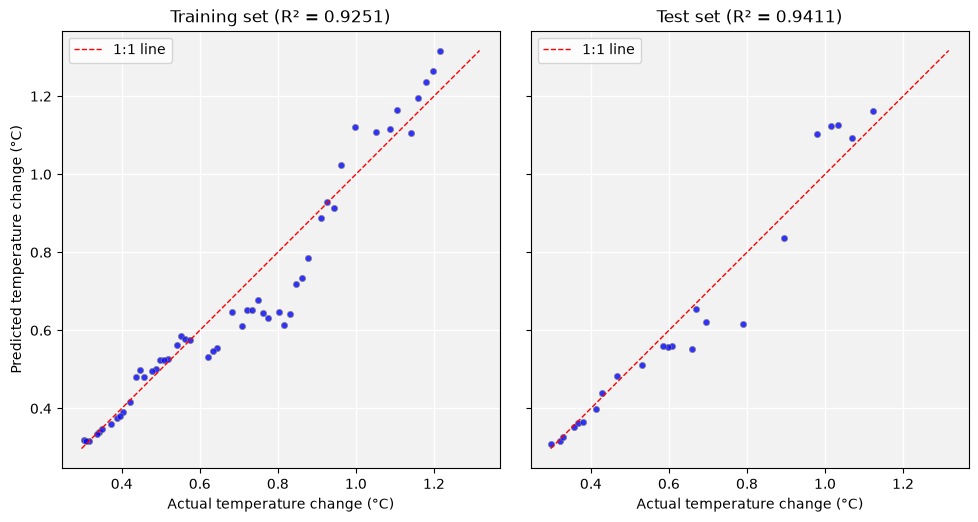

In [9]:
# Crossplots of actual vs. predicted values for the training and test sets
y_train_pred = ann.predict(X_train_scaled)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
for ax, X_set, y_true, y_hat, name in zip(
    axes,
    [X_train_scaled, X_test_scaled],
    [y_train, y_test],
    [y_train_pred, y_pred],
    ["Training", "Test"],
):
    ax.scatter(
        y_true,
        y_hat,
        c="blue",
        s=20,
        edgecolor="grey",
        linewidth=0.6,
        alpha=0.8,
    )
    ax.set_title(f"{name} set (R² = {ann.score(X_set, y_true):.4f})")
    ax.set_xlabel("Actual temperature change (°C)")

# 1:1 line: points on this line are perfect predictions
lims = [
    min(y.min(), y_train_pred.min(), y_pred.min()),
    max(y.max(), y_train_pred.max(), y_pred.max()),
]
for ax in axes:
    ax.plot(lims, lims, color="red", linestyle="--", linewidth=1, label="1:1 line")
    ax.set_aspect("equal")
    ax.legend()
axes[0].set_ylabel("Predicted temperature change (°C)")

fig.set_facecolor("white")
for ax in axes:
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white", linewidth=1)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

## 6. Model Performance Tuning: number of neurons

In [10]:
metrics = pd.DataFrame(
    {
        "n_neurons": [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 200, 300],
        "train_accuracy": [None] * 12,
        "test_accuracy": [None] * 12,
    }
)

for i, n_neurons in enumerate(metrics["n_neurons"]):
    # Fit an artificial neural network (ANN) model to the standardized training data
    ann = MLPRegressor(
        loss="squared_error",
        hidden_layer_sizes=(n_neurons,),
        activation="relu",
        solver="adam",
        learning_rate="constant",
        learning_rate_init=0.001,
        max_iter=200,
        random_state=42,  # set random seed for reproducibility, we get same results each time
    ).fit(X_train_scaled, y_train)

    # Training and test set scores
    train_score = ann.score(X_train_scaled, y_train)
    test_score = ann.score(X_test_scaled, y_test)
    metrics.loc[i, "train_accuracy"] = train_score
    metrics.loc[i, "test_accuracy"] = test_score
    print(
        f"n_neurons: {n_neurons:>3} | "
        f"Training set score: {train_score:.4f} | "
        f"Test set score: {test_score:.4f}"
    )

n_neurons:  10 | Training set score: 0.8799 | Test set score: 0.7998
n_neurons:  20 | Training set score: 0.8809 | Test set score: 0.7418
n_neurons:  30 | Training set score: 0.8667 | Test set score: 0.8977
n_neurons:  40 | Training set score: 0.9399 | Test set score: 0.9312
n_neurons:  50 | Training set score: 0.9251 | Test set score: 0.9411
n_neurons:  60 | Training set score: 0.9586 | Test set score: 0.9597
n_neurons:  70 | Training set score: 0.9485 | Test set score: 0.9546
n_neurons:  80 | Training set score: 0.9791 | Test set score: 0.9662
n_neurons:  90 | Training set score: 0.9407 | Test set score: 0.8915
n_neurons: 100 | Training set score: 0.8988 | Test set score: 0.9081
n_neurons: 200 | Training set score: 0.9616 | Test set score: 0.9646
n_neurons: 300 | Training set score: 0.6817 | Test set score: 0.6276


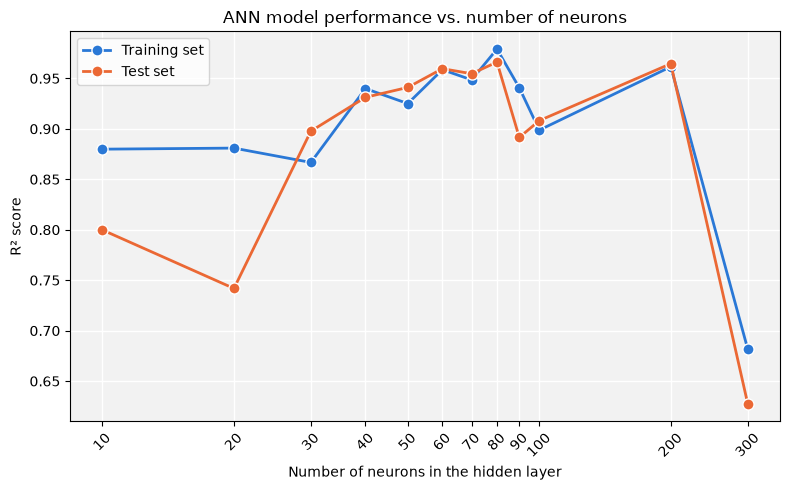

In [11]:
# Plot training and test set scores vs. number of neurons in the hidden layer
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    metrics["n_neurons"],
    metrics["train_accuracy"].astype(float),
    color="#2a78d6",
    linewidth=2,
    marker="o",
    markersize=8,
    markeredgecolor="white",
    label="Training set",
)
ax.plot(
    metrics["n_neurons"],
    metrics["test_accuracy"].astype(float),
    color="#eb6834",
    linewidth=2,
    marker="o",
    markersize=8,
    markeredgecolor="white",
    label="Test set",
)

# Log scale spreads out the small neuron counts (10-100) next to the large ones (200-500)
ax.set_xscale("log")
ax.set_xticks(metrics["n_neurons"])
ax.set_xticklabels(metrics["n_neurons"], rotation=45)
ax.minorticks_off()

ax.set_title("ANN model performance vs. number of neurons")
ax.set_xlabel("Number of neurons in the hidden layer")
ax.set_ylabel("R² score")
ax.legend()

fig.set_facecolor("white")
ax.set_facecolor("#f2f2f2")
ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()